# Engineering checks

Use the shared flight for correlated loads and control demand, then examine
propellant volume, dry-mass allocation, tank thickness, and sourced mission cases.
Every study reads [saved inputs](inputs/); nothing in this notebook silently
changes the baseline flight. Missing thermal, separation, and hardware inputs
remain visible.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from model.inputs import load_config, load_checks, load_study, load_mission_cases, input_tables, choices_table
from model.notebook import show_input_tables, show_table
from model.workspace import current_flight
from model.flight_evidence import flight_summary, sourced_sizing
from model.structures import tank_stress
from model.mission import lambert_window
from model.verification import acceptance, input_contracts
from model.outputs import input_identity, save_engineering

%matplotlib inline

## 1. Inputs

Edit [vehicle.toml](inputs/vehicle.toml) for shared vehicle geometry and loaded
masses, and [flight.toml](inputs/flight.toml) for the flight. In
[checks.toml](inputs/checks.toml), `calculations.sourced_sizing` holds tank
volumes, liquid densities, and component-mass allocations; the same file holds
study settings and acceptance rules. The thickness study is a pressure-only
screen until combined loads are supplied.

The dates below come from the resolved mission-study inputs. Original orbital
state provenance remains in [mission_cases.json](inputs/requirements/mission_cases.json).

In [2]:
run_inputs = input_identity()
config = load_config()
checks = load_checks()
thickness_study = load_study("tank_thickness")
mission_cases = load_mission_cases()
mission_inputs = checks["lambert_window"]["inputs"]
sizing_inputs = checks["sourced_sizing"]["inputs"]
ullage_rules = checks["PROP.3.TANK.02.A01"].get("acceptance", [])

show_table(pd.DataFrame(sizing_inputs["tanks"]).rename(columns={
    "name": "Tank", "volume_m3": "Tank volume (m³)",
    "loaded_mass_kg": "Liquid mass (kg)", "density_kg_m3": "Density (kg/m³)",
}).round(3))
show_table(pd.DataFrame([
    ("Tank radius", thickness_study["inputs"]["radius_m"], "m"),
    ("Differential pressure", thickness_study["inputs"]["pressure_pa"] / 1e6, "MPa"),
    ("Yield strength", thickness_study["inputs"]["yield_allowable_pa"] / 1e6, "MPa"),
    ("Load factor", thickness_study["inputs"]["load_factor"], "ratio"),
    ("Joint efficiency", thickness_study["inputs"]["joint_efficiency"], "ratio"),
    ("Thicknesses", thickness_study["thicknesses_mm"], "mm"),
], columns=["Input", "Value", "Units"]))
show_table(pd.DataFrame(ullage_rules).rename(columns={
    "metric": "Metric", "operator": "Rule", "limit": "Limit",
    "units": "Units", "source": "Source",
}))
show_table(pd.DataFrame(mission_inputs["cases"])[ ["departure_label", "arrival_label", "time_of_flight_s", "long_way"]])
show_input_tables(input_tables())

Tank,Tank volume (m³),Liquid mass (kg),Density (kg/m³)
Stage1 methane,217.891,91892.297,451.256
Stage1 LOX,271.650,330812.269,1237.800
Stage2 hydrogen,132.371,9446.264,75.130
Stage2 LOX,48.275,56677.585,1237.800


Input,Value,Units
Tank radius,2.7,m
Differential pressure,0.6,MPa
Yield strength,296.474564,MPa
Load factor,1.25,ratio
Joint efficiency,1,ratio
Thicknesses,"[1, 2, 3, 4, 5, 6]",mm


Metric,Rule,Limit,Units,Source
minimum_ullage_fraction,>=,0.04,fraction,PROP.3.TANK.02 [TBR-PROP-36]


departure_label,arrival_label,time_of_flight_s,long_way
2033-04-27 00:00 TDB,2034-01-26 00:00 TDB,23673600.0,True
2033-04-28 00:00 TDB,2034-01-27 00:00 TDB,23673600.0,True
2033-04-29 00:00 TDB,2034-01-28 00:00 TDB,23673600.0,True


Input,Value,Units,Source
vehicle.diameter_m,5.4,m,inputs/vehicle.toml → vehicle.diameter_m
vehicle.payload_kg,4313,kg,inputs/vehicle.toml → vehicle.payload_kg
vehicle.fairing_kg,2155.27825,kg,inputs/vehicle.toml → vehicle.fairing_kg
vehicle.fairing_length_m,11.5,m,inputs/vehicle.toml → vehicle.fairing_length_m
vehicle.payload_cg_above_fairing_base_m,4.5,m,inputs/vehicle.toml → vehicle.payload_cg_above_fairing_base_m
vehicle.payload_length_m,6.0,m,inputs/vehicle.toml → vehicle.payload_length_m
vehicle.payload_radius_m,1.5,m,inputs/vehicle.toml → vehicle.payload_radius_m
vehicle.fairing_cg_above_base_m,6.5,m,inputs/vehicle.toml → vehicle.fairing_cg_above_base_m
vehicle.payload_station_m,51.763013,m,inputs/vehicle.toml → vehicle.payload_station_m
vehicle.stages.0.name,Stage 1,—,inputs/vehicle.toml → vehicle.stages.0.name


...

Input,Value,Units,Source
departure.coast_duration_s,600.000000,s,inputs/flight.toml → departure.coast_duration_s
departure.restart_propellant_kg,301.843504,kg,inputs/flight.toml → departure.restart_propellant_kg (uses vehicle.stages.1.startup_propellant_kg)
departure.target_c3_km2_s2,9.800000,km²/s²,inputs/flight.toml → departure.target_c3_km2_s2
departure.max_burn_duration_s,900.000000,s,inputs/flight.toml → departure.max_burn_duration_s
departure.output_step_s,2.000000,s,inputs/flight.toml → departure.output_step_s


Input,Value,Units,Source
shared.minimum_liftoff_thrust_to_weight,1.2,—,inputs/checks.toml → shared.minimum_liftoff_thrust_to_weight


Input,Value,Units,Source
calculations.flight_summary.basis,Current integrated 6DOF ascent; provisional aero/actuator/geometry inputs. No qualification claim.,—,inputs/checks.toml → calculations.flight_summary.basis
calculations.lambert_window.basis,Three source Horizons samples; no daily launch-window optimization or site-access proof.,—,inputs/checks.toml → calculations.lambert_window.basis
calculations.lambert_window.inputs.cases.0.departure_label,2033-04-27 00:00 TDB,—,inputs/checks.toml → calculations.lambert_window.inputs.cases (uses mission_cases.cases)
calculations.lambert_window.inputs.cases.0.arrival_label,2034-01-26 00:00 TDB,—,inputs/checks.toml → calculations.lambert_window.inputs.cases (uses mission_cases.cases)
calculations.lambert_window.inputs.cases.0.time_of_flight_s,23673600.0,s,inputs/checks.toml → calculations.lambert_window.inputs.cases (uses mission_cases.cases)
calculations.lambert_window.inputs.cases.0.departure_position_m,-120881146339.1056; -82360653324.81117; -35699389120.235855,m,inputs/checks.toml → calculations.lambert_window.inputs.cases (uses mission_cases.cases)
calculations.lambert_window.inputs.cases.0.arrival_position_m,151893899759.2209; 144802306802.2028; 62324284364.44935,m,inputs/checks.toml → calculations.lambert_window.inputs.cases (uses mission_cases.cases)
calculations.lambert_window.inputs.cases.0.departure_planet_velocity_m_s,17276.96831291071; -22058.20300105831; -9560.256841566952,m/s,inputs/checks.toml → calculations.lambert_window.inputs.cases (uses mission_cases.cases)
calculations.lambert_window.inputs.cases.0.arrival_planet_velocity_m_s,-16526.05562522464; 17003.911452690558; 8244.829125552214,m/s,inputs/checks.toml → calculations.lambert_window.inputs.cases (uses mission_cases.cases)
calculations.lambert_window.inputs.cases.0.long_way,Yes,—,inputs/checks.toml → calculations.lambert_window.inputs.cases (uses mission_cases.cases)


Input,Value,Units,Source
activities.PERF.2.05.A01.basis,Requirement numeric screen only; model-validation and open source conflicts remain.,—,inputs/checks.toml → activities.PERF.2.05.A01.basis
activities.PERF.2.05.A01.acceptance.0.metric,liftoff_thrust_to_weight,—,inputs/checks.toml → activities.PERF.2.05.A01.acceptance.0.metric
activities.PERF.2.05.A01.acceptance.0.operator,>=,—,inputs/checks.toml → activities.PERF.2.05.A01.acceptance.0.operator
activities.PERF.2.05.A01.acceptance.0.limit,1.2,—,inputs/checks.toml → activities.PERF.2.05.A01.acceptance.0.limit (uses checks.shared.minimum_liftoff_thrust_to_weight)
activities.PERF.2.05.A01.acceptance.0.units,1,—,inputs/checks.toml → activities.PERF.2.05.A01.acceptance.0.units
activities.PERF.2.05.A01.acceptance.0.source,PERF.2.05,—,inputs/checks.toml → activities.PERF.2.05.A01.acceptance.0.source
activities.PERF.2.06.A01.basis,Requirement numeric screen only; model-validation and open source conflicts remain.,—,inputs/checks.toml → activities.PERF.2.06.A01.basis
activities.PERF.2.06.A01.acceptance.0.metric,max_axial_g,—,inputs/checks.toml → activities.PERF.2.06.A01.acceptance.0.metric
activities.PERF.2.06.A01.acceptance.0.operator,<=,—,inputs/checks.toml → activities.PERF.2.06.A01.acceptance.0.operator
activities.PERF.2.06.A01.acceptance.0.limit,6.0,—,inputs/checks.toml → activities.PERF.2.06.A01.acceptance.0.limit (uses limits.axial_g)


Input,Value,Units,Source
studies.tank_thickness.basis,"Pressure-only trade from Structures Sizing.xlsx, Tank Sizing!B3:D8 and Material Properties!B3:H3 (Al2219). The yield factor comes from STR.3.SYS.03; its separate ultimate factor is not evaluated here. Radius follows the selected vehicle. Material applicability, temperature, joints and combined flight loads still need review; this trade alone closes no activity.",—,inputs/checks.toml → studies.tank_thickness.basis
studies.tank_thickness.thicknesses_mm,1; 2; 3; 4; 5; 6,mm,inputs/checks.toml → studies.tank_thickness.thicknesses_mm
studies.tank_thickness.inputs.radius_m,2.7,m,inputs/checks.toml → studies.tank_thickness.inputs.radius_m (uses vehicle.diameter_m × 0.5)
studies.tank_thickness.inputs.pressure_pa,599999.764445,Pa,inputs/checks.toml → studies.tank_thickness.inputs.pressure_pa
studies.tank_thickness.inputs.axial_force_n,0,N,inputs/checks.toml → studies.tank_thickness.inputs.axial_force_n
studies.tank_thickness.inputs.bending_moment_nm,0,N m,inputs/checks.toml → studies.tank_thickness.inputs.bending_moment_nm
studies.tank_thickness.inputs.torque_nm,0,N m,inputs/checks.toml → studies.tank_thickness.inputs.torque_nm
studies.tank_thickness.inputs.yield_allowable_pa,296474563.606224,Pa,inputs/checks.toml → studies.tank_thickness.inputs.yield_allowable_pa
studies.tank_thickness.inputs.joint_efficiency,1,—,inputs/checks.toml → studies.tank_thickness.inputs.joint_efficiency
studies.tank_thickness.inputs.load_factor,1.25,—,inputs/checks.toml → studies.tank_thickness.inputs.load_factor


## 2. Choices and assumptions

Tank yield utilization compares factored stress with allowable stress. This
screen does not cover buckling, weld details, penetrations, thermal stress, or
an installed tank's combined flight loads. The sourced planet states retain
their original reference frame and timescale; three samples are not a complete
launch-window search.

In [3]:
show_table(choices_table())
print("Tank study:", thickness_study["basis"])
print("Source sizing:", checks["sourced_sizing"]["basis"])
print("Mission scope:", mission_cases["scope"])

Choice,Selection,Basis
Vehicle geometry,fairing_length_m: 11.5 m; diameter_m: 5.4 m,Selected sizing geometry. The master Payload sheet still gives a 14 m fairing; reconcile with CAD and the aero export.
CP interpretation,cp_units: inches converted to m; cp_datum: nose; RASAero-format inference,Inches are tentative user confirmation; datum is inferred and remains unverified.
Aerodynamic reference,reference_area_m2: 22.902210444669596 m²; outside_domain_policy: endpoint hold AND flag every sample; post_separation_policy: reuse full vehicle coefficients; unvalidated proxy,Source export geometry is unverified. Flag out-of-domain and separated-vehicle proxy samples.
Stage 1 control capability,gimbal_limit_deg: 5.0 deg; gimbal_rate_deg_s: 5.0 deg/s,"Assumed actuator capability, not approved hardware performance."
Stage 2 control capability,gimbal_limit_deg: 5.0 deg; gimbal_rate_deg_s: 5.0 deg/s,"Assumed actuator capability, not approved hardware performance."
Departure baseline,coast_duration_s: 600 s; restart_propellant_kg: 301.843504114127 kg; target_c3_km2_s2: 9.8 km²/s²,The verification target is provisional. The master target is retained as a separate comparison case; neither is a solved encounter.
Integrator,method: RK45; rtol: 2e-07; max_step_s: 0.4 s,Quaternion rigid-body 6DOF with discrete stage and fairing events; no flexible dynamics.
Atmosphere and wind,wind_reference_m_s: 7.62 m/s; wind_toward_deg_east_of_north: 90.0; temperature_offset_K: 0.0 K; density_scale: 1.0,Layered standard atmosphere and a deterministic wind profile; no measured launch sounding.
Coast and roll control,rcs_moment_Nm: 0.0 N m; roll_rcs_moment_Nm: 0.0 N m; control_ratio: 2.0,Evaluate all phases. No central-axis TVC roll authority is available.
Actuator response,actuator_time_constant_s: 0.15 s,Assumed first-order response; requires hardware confirmation.


Tank study: Pressure-only trade from Structures Sizing.xlsx, Tank Sizing!B3:D8 and Material Properties!B3:H3 (Al2219). The yield factor comes from STR.3.SYS.03; its separate ultimate factor is not evaluated here. Radius follows the selected vehicle. Material applicability, temperature, joints and combined flight loads still need review; this trade alone closes no activity.
Source sizing: Current Mlox-Hlox Vehicle Sizing G4:H5,F19:G20,B31:C32; Vehicle Mass E29/E44 totals plus fairing2155.27825kg and adapter replacement845−431.976225kg. Bottom-up totals retained to source precision.
Mission scope: Three daily departure samples at fixed 274 day TOF, not a comprehensive launch-window optimization.


## 3. Run

The flight is shared with Simulation. Study inputs and yield factors are read
from their saved definitions; the thickness list changes only the tank study.

In [4]:
context = current_flight()
flight, summary, simulation = context
metrics = flight_summary(context)
sizing = sourced_sizing(context=context, **sizing_inputs)

trade_rows = []
for thickness_mm in thickness_study["thicknesses_mm"]:
    result = tank_stress(**thickness_study["inputs"], thickness_m=thickness_mm / 1000)
    trade_rows.append({
        "Thickness (mm)": thickness_mm,
        "Yield utilization": result["yield"]["utilization"],
    })
thickness_trade = pd.DataFrame(trade_rows)

window = lambert_window(**mission_inputs)

## 4. Outputs

### Propellant volume and mass allocation

Ullage is the unfilled fraction of tank volume. A negative dry-mass margin means
the component rollup exceeds its allocation. The rollup preserves source fairing
and adapter bookkeeping; these are source calculations, not measured masses.

In [5]:
tanks = pd.DataFrame(sizing["tanks"])
tanks["Ullage (%)"] = tanks.pop("ullage_fraction") * 100
tanks = tanks.rename(columns={
    "tank": "Tank", "liquid_volume_m3": "Liquid volume (m³)", "tank_volume_m3": "Tank volume (m³)",
})
show_table(tanks.round(3))
sizing_passed = acceptance(sizing, ullage_rules)
verdict = {True: "Meets saved criteria", False: "Needs attention", None: "No acceptance rule supplied"}
print("Tank-sizing screen:", verdict[sizing_passed])

mass_allocation = pd.DataFrame({
    "Stage": [stage["name"] for stage in config["vehicle"]["stages"]],
    "Component rollup (kg)": sizing_inputs["component_mass_kg"],
    "Allocation (kg)": sizing_inputs["allocated_mass_kg"],
    "Margin (kg)": sizing["dry_mass_margin_kg"],
})
show_table(mass_allocation.round(3))

Tank,Liquid volume (m³),Tank volume (m³),Ullage (%)
Stage1 methane,203.637,217.891,6.542
Stage1 LOX,267.258,271.650,1.617
Stage2 hydrogen,125.732,132.371,5.015
Stage2 LOX,45.789,48.275,5.150


Tank-sizing screen: Needs attention


Stage,Component rollup (kg),Allocation (kg),Margin (kg)
Stage 1,22660.755,30673.733,8012.979
Stage 2,7783.826,7898.353,114.527


### Correlated structural loads and control demand

Keep each load-case row together. Independent maxima do not describe a real
flight condition. Available control is based on the assumed gimbal hardware;
the engine-off shortfall must remain visible when assessing the entire flight.

In [6]:
load_columns = {
    "case": "Load case", "t_s": "Time (s)", "mass_kg": "Mass (kg)",
    "normal_force_N": "Normal force (N)", "aero_moment_Nm": "Aero moment (N·m)",
    "payload_axial_force_N": "Payload axial force (N)",
    "payload_lateral_force_N": "Payload lateral force (N)",
}
load_cases = simulation.load_cases[list(load_columns)].rename(columns=load_columns)
show_table(load_cases.round(3))

control = pd.DataFrame([
    ("Peak demanded control moment", flight.required_moment_Nm.max() / 1000, "kN·m"),
    ("Peak total gimbal angle", flight.gimbal_total_deg.abs().max(), "deg"),
    ("Smallest powered control margin", metrics["minimum_powered_control_ratio_margin_Nm"] / 1000, "kN·m"),
    ("Smallest all-phase control margin", metrics["minimum_control_ratio_margin_Nm"] / 1000, "kN·m"),
    ("Additional coast control required", metrics["required_coast_control_Nm"] / 1000, "kN·m"),
], columns=["Result", "Value", "Units"])
show_table(control.round(3))

Load case,Time (s),Mass (kg),Normal force (N),Aero moment (N·m),Payload axial force (N),Payload lateral force (N)
Max-Q,63.400,409096.847,4398.162,154552.784,57030.287,164.861
Max-Qalpha,46.600,437794.108,25361.577,892656.526,60892.478,456.071
Max axial acceleration,217.763,121234.610,411.119,6382.989,240597.635,24.967
Max lateral acceleration,220.963,79947.161,525.025,2512.076,47946.665,756.543
Max aerodynamic moment,46.600,437794.108,25361.577,892656.526,60892.478,456.071
Max TVC demand,46.600,437794.108,25361.577,892656.526,60892.478,456.071
Max thrust,0.000,528757.069,144.257,5054.527,55178.853,12.617
Max aerodynamic normal force,46.600,437794.108,25361.577,892656.526,60892.478,456.071
Max aerodynamic axial force,76.400,388581.983,2050.982,70742.613,58256.421,64.259


Result,Value,Units
Peak demanded control moment,1104.477,kN·m
Peak total gimbal angle,0.933,deg
Smallest powered control margin,253.760,kN·m
Smallest all-phase control margin,-12.766,kN·m
Additional coast control required,12.766,kN·m


### Tank-thickness trade

Utilization at or below one meets this yield screen. It does not establish an
acceptable installed tank thickness.

Thickness (mm),Yield utilization
1,5.915
2,2.958
3,1.972
4,1.479
5,1.183
6,0.986


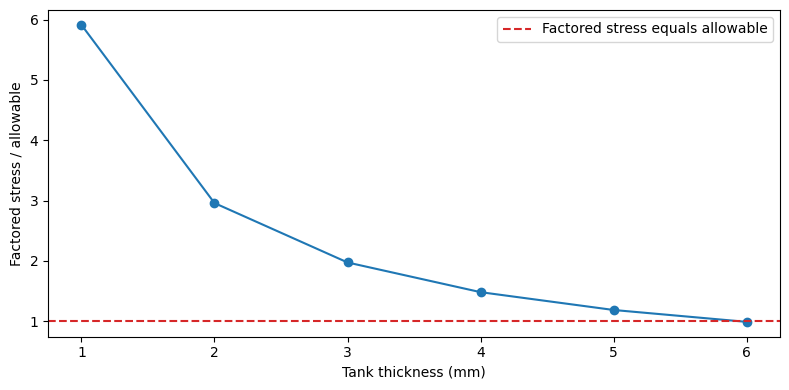

In [7]:
show_table(thickness_trade.round(3))
figure, axis = plt.subplots(figsize=(8, 4))
axis.plot(thickness_trade["Thickness (mm)"], thickness_trade["Yield utilization"], marker="o")
axis.axhline(1, color="tab:red", ls="--", label="Factored stress equals allowable")
axis.set(xlabel="Tank thickness (mm)", ylabel="Factored stress / allowable")
axis.legend()
figure.tight_layout()
figures = {"tank_thickness": figure}
display(figure)
plt.close(figure)

### Sourced departure dates

These Lambert transfers check the supplied Earth/Mars state pairs. Departure
energy, launch-site access, finite-burn targeting, and arrival geometry must be
considered together before selecting a launch window.

In [8]:
window_columns = {
    "departure_label": "Departure date",
    "departure_C3_km2_s2": "C3 (km²/s²)",
    "departure_declination_deg": "Declination (deg)",
    "arrival_excess_speed_m_s": "Arrival excess speed (m/s)",
}
window_results = pd.DataFrame(window["cases"])[list(window_columns)].rename(columns=window_columns)
show_table(window_results.round(4))

Departure date,C3 (km²/s²),Declination (deg),Arrival excess speed (m/s)
2033-04-27 00:00 TDB,7.7237,-10.3665,4375.8107
2033-04-28 00:00 TDB,7.7090,-11.3763,4376.2099
2033-04-29 00:00 TDB,7.7055,-12.4805,4376.2699


### Thermal, separation, and avionics work still needed

The functions below are available, but a function alone is not evidence.
The table lists required shared inputs still absent from the saved settings.
Activity-specific values are resolved by the [verification notebook](03_Verification.ipynb).
That notebook runs configured activities and checks their supplied acceptance rules.
The former demonstration sequence is excluded from vehicle verification.

In [9]:
next_calculations = [
    "thermal_network", "relative_separation", "systems_actuator",
    "systems_power_energy", "systems_rf_link", "systems_state_machine",
]
contracts = input_contracts().set_index("calculation")
needed_rows = []
for name in next_calculations:
    required = contracts.loc[name, "required_inputs"].split(", ")
    supplied = checks.get(name, {}).get("inputs", {})
    missing = [key for key in required if key != "context" and supplied.get(key) is None]
    needed_rows.append({
        "Calculation": name,
        "Purpose": contracts.loc[name, "description"],
        "Missing shared inputs": ", ".join(missing) or "Configured; see verification results",
    })
needed_inputs = pd.DataFrame(needed_rows)
show_table(needed_inputs)

Calculation,Purpose,Missing shared inputs
thermal_network,C dT/dt=sum Gij(Tj-Ti)+Q+H(Tamb-T)+eps*A*sigma(Tamb^4-T^4).,"times_s, heat_capacity_j_k, conductance_w_k, initial_temperature_k, heat_input_w, ambient_temperature_k, ambient_conductance_w_k, emissivity_area_m2"
relative_separation,Propagate both released bodies with equal/opposite impulse and gravity.,"position_a_m, velocity_a_m_s, position_b_m, velocity_b_m_s, mass_a_kg, mass_b_kg, impulse_on_a_N_s, duration_s, required_center_clearance_m"
systems_actuator,"First-order, rate/position-limited actuator with zero-order-held commands; times s, positions/commands in common units.","time_s, command, initial_position, time_constant_s, rate_limit_per_s, lower_limit, upper_limit"
systems_power_energy,"Electrical energy budget; loads contain power_w, duration_s, duty_fraction; capacity Wh, transfer times s.","loads, capacity_wh, usable_fraction, distribution_efficiency, reserve_fraction, transfer_time_s, allowed_transfer_time_s"
systems_rf_link,"Free-space RF link and ground antenna visibility; positions ECEF m, gains dBi, losses dB.","tx_positions_m, rx_position_m, frequency_hz, tx_power_w, tx_gain_dbi, rx_gain_dbi, loss_db, noise_temperature_k, bit_rate_bps, required_ebn0_db, minimum_elevation_deg"
systems_state_machine,"Evaluate explicit transition/guard logic; events {time_s,event,signals}, transitions {from,event,to,guards}.","initial_state, events, transitions, forbidden_states"


## 5. What the results mean

Use the load cases as inputs to detailed structural analyses, not as strength
margins. Supply documented geometry, material data, boundary conditions, release
states, hardware selections, and limits before claiming the remaining checks.

The saved [summary](outputs/current/summary.md) links findings to the
[plots](outputs/current/plots/), [tables](outputs/current/tables/), and
[settings used](outputs/current/inputs_used/). Continue to
[Verification](03_Verification.ipynb) for every required activity and missing record.

In [10]:
tables = {
    "tank_ullage": tanks, "mass_allocation": mass_allocation,
    "load_cases": load_cases, "control_demand": control,
    "tank_thickness": thickness_trade, "mission_window": window_results,
    "needed_inputs": needed_inputs,
}
output_folder = save_engineering(tables, figures=figures, expected_inputs=run_inputs)
print("Saved engineering results to:", output_folder)

Saved engineering results to: C:\Users\maxwe\.codex\.chatgpt-projects\g-p-6a9464860c90819188ae3dd3be539576\Hyperion\outputs\current
